In [1]:
import os
import random
import numpy as np
import pandas as pd

SEED = 123

random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "/kaggle/input/datasets/rpghost/scaffold-regression"
OUTPUT_DIR = "/kaggle/working/xgboost_regression"

os.makedirs(OUTPUT_DIR, exist_ok=True)

train_df = pd.read_csv(f"{DATA_DIR}/train_regression.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val_regression.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test_regression.csv")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {df.shape}")
    print("Columns:", df.columns.tolist())

    assert df["smiles"].notna().all()
    assert df["median_pIC50"].notna().all()
    assert np.isfinite(df["median_pIC50"]).all()

print("\nRegression splits loaded successfully.")


Train: (7402, 3)
Columns: ['inchi_key', 'smiles', 'median_pIC50']

Validation: (948, 3)
Columns: ['inchi_key', 'smiles', 'median_pIC50']

Test: (1941, 3)
Columns: ['inchi_key', 'smiles', 'median_pIC50']

Regression splits loaded successfully.


In [3]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 40.8 MB/s eta 0:00:00:00:0100:01


In [4]:
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from tqdm.auto import tqdm

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def smiles_to_fingerprints(smiles_list):
    fingerprints = []

    for smiles in tqdm(smiles_list, desc="Generating fingerprints"):
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            raise ValueError(f"Invalid SMILES encountered: {smiles}")

        fp = morgan_generator.GetFingerprint(mol)

        arr = np.zeros(2048, dtype=np.uint8)
        DataStructs.ConvertToNumpyArray(fp, arr)
        fingerprints.append(arr)

    return np.asarray(fingerprints, dtype=np.uint8)


X_train = smiles_to_fingerprints(train_df["smiles"].tolist())
X_val = smiles_to_fingerprints(val_df["smiles"].tolist())
X_test = smiles_to_fingerprints(test_df["smiles"].tolist())

y_train = train_df["median_pIC50"].to_numpy(dtype=np.float32)
y_val = val_df["median_pIC50"].to_numpy(dtype=np.float32)
y_test = test_df["median_pIC50"].to_numpy(dtype=np.float32)

print("\nFeature shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Generating fingerprints:   0%|          | 0/7402 [00:00<?, ?it/s]

Generating fingerprints:   0%|          | 0/948 [00:00<?, ?it/s]

Generating fingerprints:   0%|          | 0/1941 [00:00<?, ?it/s]


Feature shapes:
Train: (7402, 2048) (7402,)
Validation: (948, 2048) (948,)
Test: (1941, 2048) (1941,)


In [5]:
from itertools import product
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

# Evaluate regression predictions
def regression_metrics(y_true, y_pred):
    pearson_result = pearsonr(y_true, y_pred)
    spearman_result = spearmanr(y_true, y_pred)

    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
        "Pearson_r": float(pearson_result.statistic),
        "Spearman_r": float(spearman_result.statistic)
    }


# Hyperparameter combinations based on the classification notebook
param_grid = list(product(
    [3, 4, 5],       # max_depth
    [1, 3],          # min_child_weight
    [0.03, 0.05]     # learning_rate
))

results = []
best_model = None
best_val_rmse = float("inf")
best_params = None
best_val_pred = None

for trial, (max_depth, min_child_weight, learning_rate) in enumerate(
    param_grid, start=1
):
    model = XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        n_estimators=600,
        max_depth=max_depth,
        min_child_weight=min_child_weight,
        learning_rate=learning_rate,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2.0,
        random_state=SEED,
        n_jobs=-1,
        tree_method="hist"
    )

    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    metrics = regression_metrics(y_val, val_pred)

    result = {
        "trial": trial,
        "max_depth": max_depth,
        "min_child_weight": min_child_weight,
        "learning_rate": learning_rate,
        **{f"val_{k}": v for k, v in metrics.items()}
    }
    results.append(result)

    print(
        f"Trial {trial:02d}/{len(param_grid)} | "
        f"depth={max_depth} | "
        f"child_weight={min_child_weight} | "
        f"lr={learning_rate} | "
        f"Val RMSE={metrics['RMSE']:.4f} | "
        f"Val MAE={metrics['MAE']:.4f} | "
        f"Val R2={metrics['R2']:.4f}"
    )

    if metrics["RMSE"] < best_val_rmse:
        best_val_rmse = metrics["RMSE"]
        best_model = model
        best_params = {
            "max_depth": max_depth,
            "min_child_weight": min_child_weight,
            "learning_rate": learning_rate
        }
        best_val_pred = val_pred.copy()

results_df = pd.DataFrame(results).sort_values("val_RMSE")
results_df.to_csv(
    f"{OUTPUT_DIR}/hyperparameter_search.csv",
    index=False
)

print("\nBest hyperparameters:")
print(best_params)
print(f"Best validation RMSE: {best_val_rmse:.4f}")

display(results_df.head(10))

Trial 01/12 | depth=3 | child_weight=1 | lr=0.03 | Val RMSE=0.9378 | Val MAE=0.6490 | Val R2=0.2568
Trial 02/12 | depth=3 | child_weight=1 | lr=0.05 | Val RMSE=0.8753 | Val MAE=0.6101 | Val R2=0.3526
Trial 03/12 | depth=3 | child_weight=3 | lr=0.03 | Val RMSE=0.9425 | Val MAE=0.6507 | Val R2=0.2493
Trial 04/12 | depth=3 | child_weight=3 | lr=0.05 | Val RMSE=0.8797 | Val MAE=0.6100 | Val R2=0.3460
Trial 05/12 | depth=4 | child_weight=1 | lr=0.03 | Val RMSE=0.8772 | Val MAE=0.6081 | Val R2=0.3497
Trial 06/12 | depth=4 | child_weight=1 | lr=0.05 | Val RMSE=0.8145 | Val MAE=0.5699 | Val R2=0.4393
Trial 07/12 | depth=4 | child_weight=3 | lr=0.03 | Val RMSE=0.8787 | Val MAE=0.6070 | Val R2=0.3475
Trial 08/12 | depth=4 | child_weight=3 | lr=0.05 | Val RMSE=0.8091 | Val MAE=0.5695 | Val R2=0.4467
Trial 09/12 | depth=5 | child_weight=1 | lr=0.03 | Val RMSE=0.8376 | Val MAE=0.5824 | Val R2=0.4071
Trial 10/12 | depth=5 | child_weight=1 | lr=0.05 | Val RMSE=0.7574 | Val MAE=0.5398 | Val R2=0.5152


,trial,max_depth,min_child_weight,learning_rate,val_RMSE,val_MAE,val_R2,val_Pearson_r,val_Spearman_r
9,10,5,1,0.05,0.757401,0.539785,0.515181,0.782964,0.685507
11,12,5,3,0.05,0.787527,0.551030,0.475847,0.757876,0.685126
7,8,4,3,0.05,0.809115,0.569485,0.446716,0.749870,0.674881
5,6,4,1,0.05,0.814548,0.569914,0.439261,0.745565,0.672493
8,9,5,1,0.03,0.837580,0.582438,0.407102,0.736473,0.671789
10,11,5,3,0.03,0.843895,0.584000,0.398128,0.723232,0.668160
1,2,3,1,0.05,0.875263,0.610065,0.352552,0.688783,0.630375
4,5,4,1,0.03,0.877181,0.608053,0.349712,0.697552,0.644717
6,7,4,3,0.03,0.878657,0.606984,0.347522,0.691843,0.644787
3,4,3,3,0.05,0.879710,0.610028,0.345956,0.679593,0.636920


In [6]:
# Predictions from the best validation-selected model
best_test_pred = best_model.predict(X_test)

val_metrics = regression_metrics(y_val, best_val_pred)
test_metrics = regression_metrics(y_test, best_test_pred)

metrics_df = pd.DataFrame([
    {"Split": "Validation", **val_metrics},
    {"Split": "Test", **test_metrics}
])

print("Final regression metrics:")
display(metrics_df.round(4))

metrics_df.to_csv(
    f"{OUTPUT_DIR}/regression_metrics.csv",
    index=False
)

Final regression metrics:


,Split,RMSE,MAE,R2,Pearson_r,Spearman_r
0,Validation,0.7574,0.5398,0.5152,0.783,0.6855
1,Test,0.6825,0.4931,0.4009,0.639,0.5754


In [7]:
def make_prediction_df(df, predictions):
    output = pd.DataFrame({
        "smiles": df["smiles"].to_numpy(),
        "actual_pIC50": df["median_pIC50"].to_numpy(),
        "predicted_pIC50": predictions
    })

    # Preserve compound identifiers for matching predictions later
    if "inchi_key" in df.columns:
        output.insert(0, "inchi_key", df["inchi_key"].to_numpy())

    return output


val_predictions_df = make_prediction_df(val_df, best_val_pred)
test_predictions_df = make_prediction_df(test_df, best_test_pred)

val_predictions_df.to_csv(
    f"{OUTPUT_DIR}/val_evaluated_predictions.csv",
    index=False
)

test_predictions_df.to_csv(
    f"{OUTPUT_DIR}/test_evaluated_predictions.csv",
    index=False
)

best_model.save_model(
    f"{OUTPUT_DIR}/xgboost_regression.json"
)

print("Saved files:")
print(os.listdir(OUTPUT_DIR))

Saved files:
['test_evaluated_predictions.csv', 'hyperparameter_search.csv', 'regression_metrics.csv', 'val_evaluated_predictions.csv', 'xgboost_regression.json']


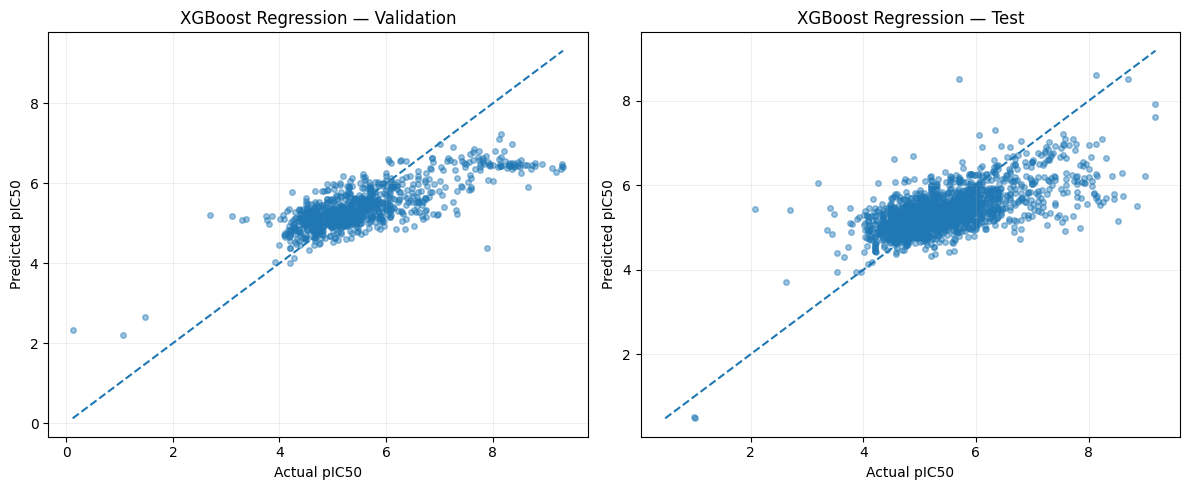

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data = [
    (axes[0], y_val, best_val_pred, "Validation"),
    (axes[1], y_test, best_test_pred, "Test")
]

for ax, actual, predicted, split_name in plot_data:
    ax.scatter(actual, predicted, alpha=0.45, s=16)

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--"
    )

    ax.set_xlabel("Actual pIC50")
    ax.set_ylabel("Predicted pIC50")
    ax.set_title(f"XGBoost Regression — {split_name}")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()